# 2 EDA
## Alcance de este análisis exploratorio

La exploración de los datos incluyó rutas que este cuaderno no desarrolla:
distribuciones de duración y distancia de viaje, perfiles de usuario,
comparaciones interanuales, validaciones de calidad de cada fuente y otros
diagnósticos descriptivos realizados durante la fase de familiarización y
en el propio ETL. Por legibilidad, este documento condensa únicamente el
análisis pertinente a la pregunta que guía el proyecto: **¿hacia dónde debe
expandirse la red de EcoBici?**

Bajo ese alcance, el EDA se organiza para establecer tres hechos
independientes que el diseño de los motores posteriores debe resolver:

1. **La cobertura es insuficiente.** La gran mayoría de las AGEBs —y de la
   población registrada en ellas— no contiene ninguna estación. La red
   existente se concentra en una fracción pequeña del territorio, y la
   distancia característica entre las zonas desatendidas y la estación más
   cercana supera con creces un radio caminable útil.
2. **La actividad observada se concentra.** El uso no se reparte
   uniformemente entre las estaciones instaladas: existe un subconjunto
   reducido de estaciones y AGEBs —el «clúster dorado»— que concentra una
   proporción desproporcionada de la actividad, con autocorrelación
   espacial positiva.
3. **El entorno distingue dónde funciona el servicio.** La actividad se
   asocia con el entorno de cada estación —transporte masivo cercano,
   actividad económica— más que con la densidad residencial. Esta
   asociación es descriptiva y sirve para formular hipótesis de
   similitud, no para afirmar causas.

En conjunto, el análisis descriptivo justifica el planteamiento central:
el problema no es únicamente «dónde falta cobertura», sino dónde una
expansión puede heredar las condiciones que hacen activas a las estaciones
existentes **sin quedar desconectada de la red que las hace útiles**. Los
diagnósticos de equidad, conectividad y dinámica horaria de este cuaderno
alimentan directamente esa pregunta; el resto de la exploración queda
documentado en las bitácoras y auditorías del proyecto.

## 1. Fuentes verificadas y reglas reproducibles

La implementación separa cálculo, presentación y publicación. Los parámetros,
versiones y hashes del código analítico se registran junto con los hashes de
los insumos. La asignación estación–AGEB exige una relación única; cualquier
pérdida o duplicación detiene el análisis antes de producir resultados.

In [15]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, JSON

BASE = Path.cwd().resolve()
PROJECT = next(p / "4_proyecto" for p in [BASE, *BASE.parents] if (p / "4_proyecto/V3/data").is_dir())
V3_DIR = PROJECT / "V3"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from V3.src.eda02_analysis import CONFIG, load_inputs, analyze
from V3.src.eda02_publication import stage_results

GREEN, GRAY, BLUE = "#004731", "#546E7A", "#0D47A1"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
data = load_inputs(V3_DIR)
result = analyze(data)
report = result["report"]
display(pd.DataFrame([{"contract_id": report["contract_id"],
                       "analysis_version": report["schema_version"],
                       "n_stations": len(result["stations"]),
                       "n_agebs": len(result["agebs"])}]))

,contract_id,analysis_version,n_stations,n_agebs
0,6e586b3d9a0bd8b844d9cf5bc714f0e583fc2a6936f8cd...,v3-eda-2,677,2452


## 2. Retención de registros y definición de actividad

La retención expresa cumplimiento de reglas del ETL, no una certificación de
veracidad, representatividad o «pureza» estadística. La cuarentena incluye
identificadores no utilizables y registros fuera del período, algunos legítimos
bajo otro universo temporal. No se atribuye una función de mantenimiento a
códigos ausentes del catálogo sin evidencia documental.



In [16]:
accounting = report["sample_accounting"]
display(pd.Series(accounting, name="value").to_frame())
display(Markdown(
    f"**Resultado.** Se aceptaron {accounting['accepted_rows']:,} de "
    f"{accounting['input_rows']:,} filas ({accounting['retention_percent']:.6f}%). "
    f"La cuarentena conserva {accounting['quarantine_rows']:,} filas. "
    f"La suma de actividad corresponde a "
    f"{accounting['endpoint_activity_trip_equivalents']:,.0f} equivalentes "
    "de viaje por extremos; no se identifica con el número de viajes completos."
))

,value
accepted_rows,20133540
input_rows,20134900
quarantine_rows,1360
valid_arribos,20134527
valid_retiros,20134368
retention_percent,99.993246
known_withdrawal_events,20134302.0
known_arrival_events,20134000.0
endpoint_activity_trip_equivalents,20134151.0
activity_is_latent_demand,False


**Resultado.** Se aceptaron 20,133,540 de 20,134,900 filas (99.993246%). La cuarentena conserva 1,360 filas. La suma de actividad corresponde a 20,134,151 equivalentes de viaje por extremos; no se identifica con el número de viajes completos.

## 3. Distribución de actividad y observaciones extremas

El IQR identifica estaciones de actividad elevada sin excluirlas. El percentil
85 define una cohorte descriptiva denominada Golden Cluster; no identifica
productividad causal ni rentabilidad. El histograma conserva la distribución
observada y las estaciones extremas. Un resultado atípico no equivale a un error.

,value
n_stations,677.000000
mean_daily_activity,81.480144
median_daily_activity,66.464384
q1,43.721918
q3,101.036986
upper_fence,187.009589
p85,127.618356
calendar_denominator_days,365.000000


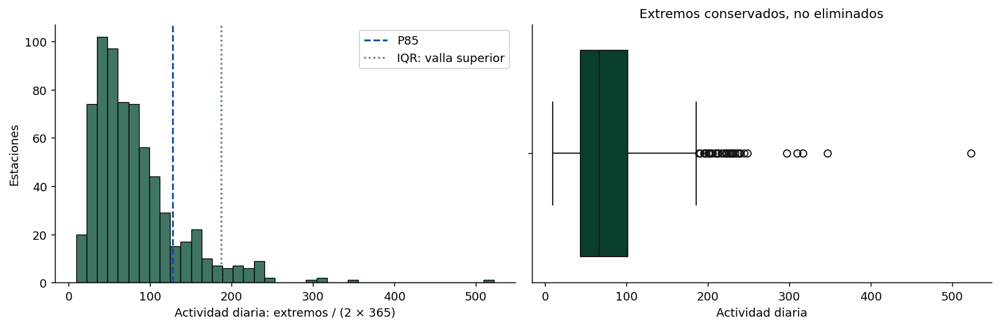

In [17]:
target = report["target_metrics"]
y = result["stations"]["viajes_diarios_prom"].to_numpy(dtype=float)
display(pd.Series(target, name="value").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=40, ax=axes[0], color=GREEN)
axes[0].axvline(target["p85"], color=BLUE, ls="--", label="P85")
axes[0].axvline(target["upper_fence"], color=GRAY, ls=":", label="IQR: valla superior")
axes[0].set(xlabel="Actividad diaria: extremos / (2 × 365)", ylabel="Estaciones")
axes[0].legend()
sns.boxplot(x=y, ax=axes[1], color=GREEN)
axes[1].set(xlabel="Actividad diaria", title="Extremos conservados, no eliminados")
plt.tight_layout(); plt.show()

### 3.1. Dinámica intradiaria: laborables y fines de semana

El pulso horario se calcula sobre retiros y arribos válidos de 2025 asociados
al catálogo, conservando la misma cohorte de extremos del diagnóstico anual.
Se leen por bloques los doce meses aceptados y se incorporan los extremos
válidos conocidos de viajes en cuarentena con sus pesos fraccionales. No
se cuentan códigos desconocidos ni se duplican estaciones con alias.
La suma horaria debe coincidir con los totales anuales ETL de cada rol.

Cada extremo utiliza su propia fecha y hora local de Ciudad de México.
Laborables significa lunes a viernes, incluyendo feriados; fin de semana
significa sábado y domingo. Se divide cada conteo horario entre el número
de días de su clase durante 2025, incluyendo días sin registros. Así la
comparación no confunde cinco días semanales con dos.

Los picos AM/PM permiten explorar compatibilidad con movilidad pendular;
una concentración diurna en fines de semana puede ser compatible con usos
recreativos. La curva no identifica propósitos individuales de viaje ni
mide demanda latente o inventario disponible.

,value
retiros_known_endpoint_weight,20134302.0
retiros_weekday_peak_hour,18
retiros_weekday_top_three_hours,"[18, 17, 8]"
retiros_weekend_peak_hour,13
retiros_weekend_top_three_hours,"[13, 12, 11]"
arribos_known_endpoint_weight,20134000.0
arribos_weekday_peak_hour,18
arribos_weekday_top_three_hours,"[18, 8, 17]"
arribos_weekend_peak_hour,13
arribos_weekend_top_three_hours,"[13, 12, 14]"


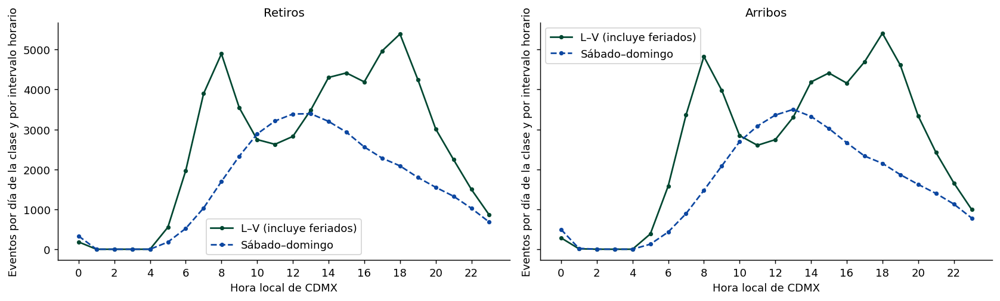

**Resultado.** La suma horaria conserva 20,134,302 retiros y 20,134,000 arribos conocidos. Se normaliza por 261 días L–V y 104 días de fin de semana.

In [18]:
from V3.src.eda02_urban import (
    URBAN_VERSION, URBAN_CONFIG, hourly_profile, census_population, modal_proximity,
)

hourly, temporal_info = hourly_profile(data)
result["hourly_profile"] = hourly
report["urban_enrichment"] = {"version": URBAN_VERSION,
                             "configuration": URBAN_CONFIG}
report["temporal_dynamics"] = temporal_info
display(pd.Series(temporal_info, name="value").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
labels = {"weekday": "L–V (incluye feriados)", "weekend": "Sábado–domingo"}
for ax, role in zip(axes, ["retiros", "arribos"]):
    for day_type, color, style in [("weekday", GREEN, "-"), ("weekend", BLUE, "--")]:
        subset = hourly[(hourly.role == role) & (hourly.day_type == day_type)]
        ax.plot(subset.hour_local, subset.events_per_calendar_day_at_hour,
                color=color, ls=style, marker="o", ms=3, label=labels[day_type])
    ax.set(title=role.capitalize(), xlabel="Hora local de CDMX",
           ylabel="Eventos por día de la clase y por intervalo horario",
           xticks=list(range(0, 24, 2)))
    ax.legend()
plt.tight_layout(); plt.show()
display(Markdown(
    "**Resultado.** La suma horaria conserva "
    f"{temporal_info['retiros_known_endpoint_weight']:,.0f} retiros y "
    f"{temporal_info['arribos_known_endpoint_weight']:,.0f} arribos conocidos. "
    f"Se normaliza por {temporal_info['calendar_weekdays']} días L–V y "
    f"{temporal_info['calendar_weekend_days']} días de fin de semana."
))

**Nota metodológica: el coeficiente de Gini.**

El coeficiente de Gini es una medida de concentración con valores entre 0 y 1.
Originalmente se emplea para describir la distribución del ingreso; aquí se
adapta para describir la distribución de las 677 estaciones entre las 2,452
AGEBs de la Ciudad de México.

- **Gini = 0** correspondería a una distribución uniforme: cada AGEB tendría
  la misma proporción de estaciones.
- **Gini = 1** correspondería a concentración máxima: una sola AGEB
  contendría todas las estaciones.
- El valor observado se ubica en un extremo: indica que la infraestructura
  se acumula en una fracción muy pequeña de los polígonos territoriales.

La gráfica asociada es la **curva de Lorenz**. El eje horizontal acumula el
porcentaje de AGEBs, ordenadas de menor a mayor número de estaciones; el eje
vertical acumula el porcentaje de estaciones que esas AGEBs contienen. La
diagonal representa la distribución uniforme de referencia. Cuanto más se
aleja la curva de esa diagonal, mayor es el Gini. En este caso, la curva
permanece pegada al eje horizontal durante la mayor parte del recorrido —el
~90% de las AGEBs no contiene ninguna estación— y despega solo al final,
cuando entran las 243 AGEBs que concentran toda la red.

**Alcance del indicador.** Este Gini pesa polígonos, no personas: cada AGEB
cuenta como una unidad independientemente de su población o su extensión.
Por ello describe *concentración de infraestructura por unidad territorial*;
no mide equidad de acceso per cápita ni distancia caminable de los
residentes. La magnitud poblacional de las AGEBs sin estación interna se
cuantifica por separado en la sección de población censal.

## 4. Concentración de infraestructura entre polígonos

El Gini utiliza conteos brutos de estaciones por AGEB, incluyendo ceros, y
pondera cada polígono por igual. No es un indicador per cápita ni una medida
completa de equidad de acceso. La línea de Lorenz representa reparto uniforme
entre AGEBs, no un criterio normativo de distribución óptima. Las proporciones
acumuladas utilizan los puntos 0, 1/n, …, n/n.

«Sin estación interna» describe pertenencia geométrica: una estación situada
en un polígono vecino puede ser accesible. Ni la proporción de AGEBs ni el Gini
deben interpretarse como proporción de habitantes excluidos. Las AGEBs rurales
conservan población desconocida; no se sustituyen esos faltantes por cero.

,value
total_agebs,2452
agebs_with_internal_station,243
agebs_without_internal_station,2209
gini_stations,0.929614
gini_activity,0.944866
gini_unit,"equal-weight AGEB polygons; raw counts, not pe..."
population_access_equity_measured,False


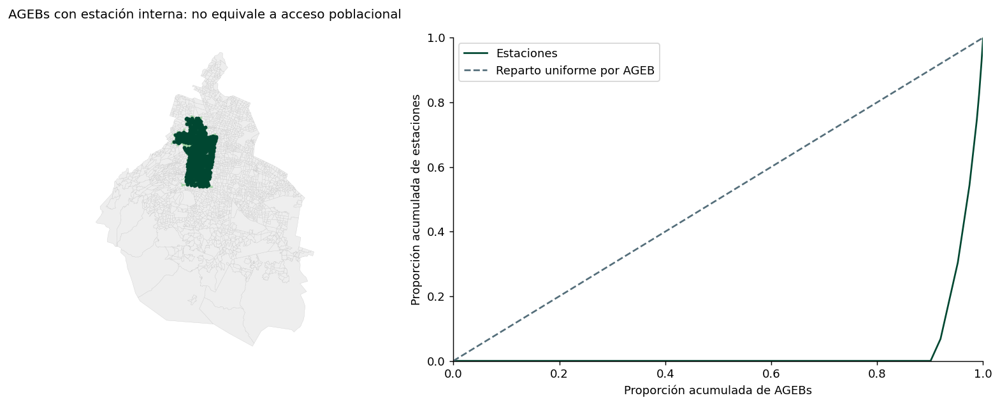

In [19]:
display(pd.Series(report["spatial_equity"], name="value").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
agebs = result["agebs"]
agebs.plot(ax=axes[0], color="#EEEEEE", edgecolor="#CCCCCC", linewidth=0.2)
agebs[agebs.n_estaciones.gt(0)].plot(ax=axes[0], color="#A5D6A7")
result["stations"].plot(ax=axes[0], color=GREEN, markersize=5)
axes[0].set_title("AGEBs con estación interna: no equivale a acceso poblacional")
axes[0].set_axis_off()
axes[1].plot(result["lorenz_x"], result["lorenz_y"], color=GREEN, label="Estaciones")
axes[1].plot([0, 1], [0, 1], "--", color=GRAY, label="Reparto uniforme por AGEB")
axes[1].set(xlabel="Proporción acumulada de AGEBs",
            ylabel="Proporción acumulada de estaciones", xlim=(0, 1), ylim=(0, 1))
axes[1].legend(); plt.tight_layout(); plt.show()

**Nota metodológica: Gini ponderado por población.**

El Gini anterior pesa *polígonos*: cada AGEB cuenta como una unidad sin
importar cuántas personas habita. Como contraste, esta curva pondera por
población censal. Las AGEBs se ordenan de menor a mayor *estaciones por
habitante*; el eje horizontal acumula el porcentaje de **población** y el
vertical el porcentaje de **estaciones** que esa población concentra.

Lectura: si el 50% de la población acumula solo el 5% de las estaciones,
la curva queda muy por debajo de la diagonal. Las 22 AGEBs con población
censal desconocida se excluyen del cálculo —no se imputan con cero— y se
reportan aparte. Al igual que el Gini territorial, este indicador mide
concentración de infraestructura *dentro del polígono de residencia*;
no mide distancia caminable ni acceso a estaciones en AGEBs vecinas.

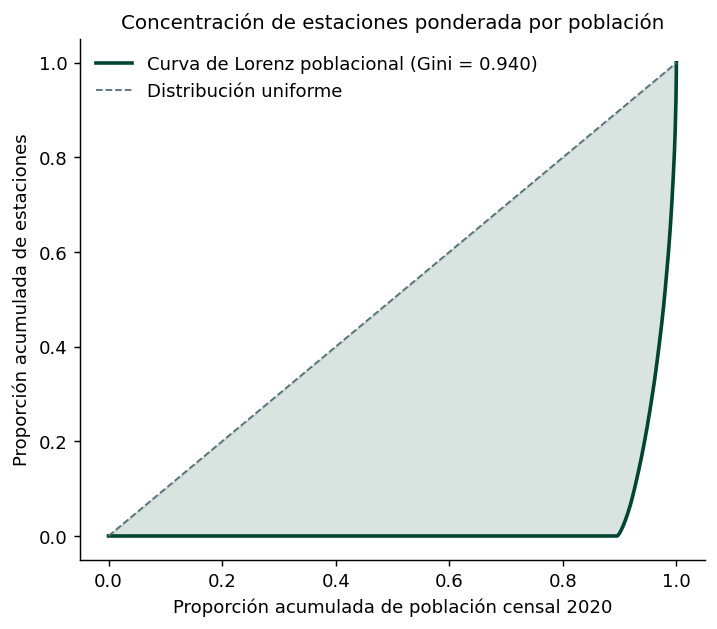

**Gini poblacional = 0.940** (vs. Gini territorial por polígono = 0.930). Calculado sobre 2,430 AGEBs con `POBTOT` conocido; se excluyen 22 AGEBs con población desconocida, sin imputar ceros.

In [20]:
# Gini ponderado por población: ordena AGEBs por estaciones per cápita
# y acumula población (eje x) contra estaciones (eje y).
# Autocontenido: enlaza el Censo 2020 aquí mismo (no depende de celdas posteriores).
census_root = V3_DIR / "data/processed" / report["contract_id"]
census = pd.read_parquet(census_root / "censo_ageb_2020.parquet",
                         columns=["cvegeo", "POBTOT", "nivel_geografico"])
census = census.loc[census.nivel_geografico.eq("ageb"), ["cvegeo", "POBTOT"]]

pop_agebs = result["agebs"][["cvegeo", "n_estaciones"]].merge(
    census.rename(columns={"POBTOT": "POBTOT_censo2020"}),
    on="cvegeo", how="left", validate="one_to_one")
pop_agebs["POBTOT_censo2020"] = pop_agebs.POBTOT_censo2020.astype("Int64")
pop_agebs["population_known"] = pop_agebs.POBTOT_censo2020.notna()

known = pop_agebs.loc[pop_agebs.population_known].copy()
unknown_n = int((~pop_agebs.population_known).sum())

known["est_per_capita"] = (
    known.n_estaciones.astype("Float64") / known.POBTOT_censo2020.astype("Float64"))
known = known.sort_values("est_per_capita", kind="stable")

x = np.r_[0.0, np.cumsum(known.POBTOT_censo2020.astype(float))
          / known.POBTOT_censo2020.astype(float).sum()]
y = np.r_[0.0, np.cumsum(known.n_estaciones.astype(float))
          / known.n_estaciones.astype(float).sum()]
gini_pop = float(1 - 2 * np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.plot(x, y, color=GREEN, lw=2,
        label=f"Curva de Lorenz poblacional (Gini = {gini_pop:.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="Distribución uniforme")
ax.fill_between(x, x, y, color=GREEN, alpha=0.15)
ax.set_xlabel("Proporción acumulada de población censal 2020")
ax.set_ylabel("Proporción acumulada de estaciones")
ax.set_title("Concentración de estaciones ponderada por población")
ax.legend(loc="upper left", frameon=False)
plt.show()

display(Markdown(
    f"**Gini poblacional = {gini_pop:.3f}** (vs. Gini territorial por polígono = "
    f"{report['spatial_equity']['gini_stations']:.3f}). "
    f"Calculado sobre {len(known):,} AGEBs con `POBTOT` conocido; "
    f"se excluyen {unknown_n} AGEBs con población desconocida, sin imputar ceros."
))

### 4.1. Magnitud humana: residentes censales en AGEBs sin estación interna

Se enlazan exactamente los polígonos identificados como sin estación interna
con los totales AGEB del Censo 2020 por la llave cvegeo. Se utiliza POBTOT,
sin sumar manzanas, municipios y AGEBs entre sí. El enlace exige unicidad
de ambas tablas y mantiene las AGEBs sin población disponible.

La suma corresponde a habitantes registrados en 2020 dentro de esos
polígonos, contrastados con la red del catálogo posterior: no es una
estimación demográfica de 2025 ni prueba ausencia de acceso caminable.
Si existen polígonos sin población conocida, se reporta el subtotal
documentado y el número de faltantes, nunca un cero imputado. Esta magnitud
social complementa el Gini de infraestructura, pero no lo convierte en Gini
poblacional ni demuestra por sí sola segregación o injusticia causal.

,cohort,n_agebs,population_known_agebs,population_unknown_agebs,population_total_known,rural_agebs
0,with_internal_station,243,243,0,953307,0
1,without_internal_station,2209,2187,22,8185081,22
2,all_polygons,2452,2430,22,9138388,22


**Magnitud social.** Existen 8.185 millones de habitantes registrados en el Censo 2020 (8,185,081) viviendo en las AGEBs sin estación interna del catálogo analizado. El subtotal no incluye población desconocida de 22 AGEBs. No mide distancia caminable exacta ni población actualizada a 2025.

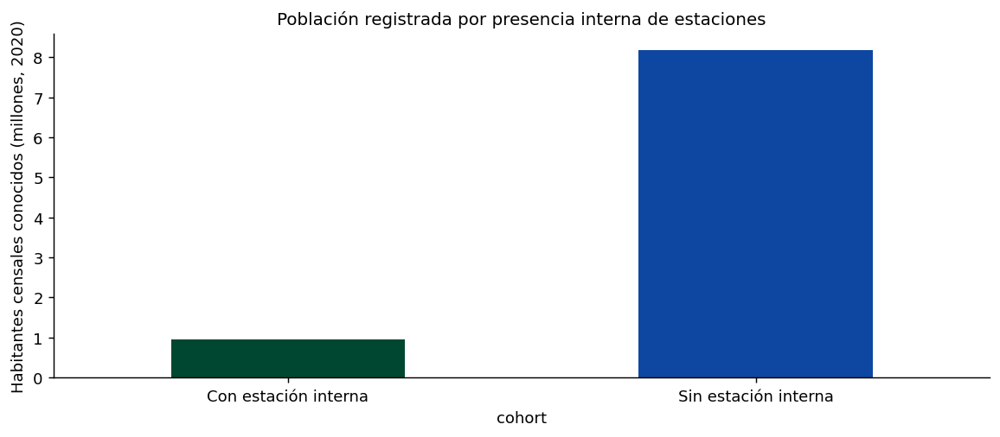

In [21]:
census_root = V3_DIR / "data/processed" / report["contract_id"]
census = pd.read_parquet(census_root / "censo_ageb_2020.parquet",
                         columns=["cvegeo", "POBTOT", "nivel_geografico"])
population_agebs, population_summary, human_info = census_population(census, agebs)
result["population_by_ageb"] = population_agebs
result["population_summary"] = population_summary
report["human_dimension"] = human_info
display(population_summary)
population_value = human_info["population_without_internal_station_known"]
unknown = human_info["unknown_population_without_internal_station_agebs"]
if population_value is None:
    human_statement = "No se dispone de población conocida para calcular el subtotal."
else:
    human_statement = (
        f"Existen {population_value / 1_000_000:.3f} millones de habitantes "
        f"registrados en el Censo 2020 ({population_value:,}) viviendo en "
        "las AGEBs sin estación interna del catálogo analizado."
    )
display(Markdown(
    "**Magnitud social.** " + human_statement +
    f" El subtotal no incluye población desconocida de {unknown} AGEBs. "
    "No mide distancia caminable exacta ni población actualizada a 2025."
))
known_population = population_summary[population_summary.cohort != "all_polygons"].copy()
ax = (known_population.set_index("cohort").population_total_known / 1_000_000).plot.bar(
    color=[GREEN, BLUE], figsize=(9, 4), rot=0)
ax.set_xticklabels(["Con estación interna", "Sin estación interna"])
ax.set(ylabel="Habitantes censales conocidos (millones, 2020)",
       title="Población registrada por presencia interna de estaciones")
plt.tight_layout(); plt.show()

## 5. Distancia de centroide a red

Se calcula distancia euclidiana en EPSG:32614 desde el centroide de cada AGEB
sin estación interna hasta el catálogo actual. Es un diagnóstico no ponderado
por población, no distancia caminable ni distancia desde un sitio factible.
Los centroides de polígonos cóncavos o multipartes pueden quedar fuera de ellos.
El radio de 400 m solo ilustra que ausencia interna y proximidad son distintos;
no constituye un umbral calibrado de servicio o de separación eficiente.

Una mediana distante motiva investigar corredores y conectividad. No prueba
imposibilidad matemática de expansión continua ni necesidad de Node2Vec.

,value
unit,unweighted AGEB centroid to nearest current ca...
median_km,6.435364
mean_km,7.117685
p75_km,9.920399
centroids_outside_own_polygon,51
no_internal_station_but_centroid_within_400m,50
continuous_expansion_impossibility_established,False


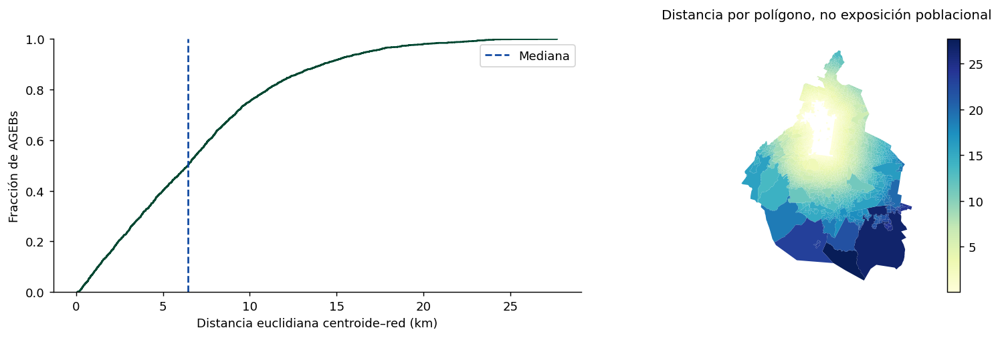

**Resultado.** Mediana: 6.44 km. 51 centroides quedan fuera de su polígono; 50 AGEBs sin estación interna tienen su centroide a 400 m o menos de una estación.

In [22]:
gap = report["territorial_gap"]
display(pd.Series(gap, name="value").to_frame())
unserved = agebs[agebs.n_estaciones.eq(0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.ecdfplot(unserved.dist_centroide_red_km, ax=axes[0], color=GREEN)
axes[0].axvline(gap["median_km"], color=BLUE, ls="--", label="Mediana")
axes[0].set(xlabel="Distancia euclidiana centroide–red (km)", ylabel="Fracción de AGEBs")
axes[0].legend()
unserved.plot(column="dist_centroide_red_km", ax=axes[1], legend=True, cmap="YlGnBu")
axes[1].set_title("Distancia por polígono, no exposición poblacional")
axes[1].set_axis_off(); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Resultado.** Mediana: {gap['median_km']:.2f} km. "
    f"{gap['centroids_outside_own_polygon']} centroides quedan fuera de su polígono; "
    f"{gap['no_internal_station_but_centroid_within_400m']} AGEBs sin estación interna "
    "tienen su centroide a 400 m o menos de una estación."
))

**Nota metodológica: el I de Moran.**

El I de Moran es la medida clásica de **autocorrelación espacial**: cuantifica
si observaciones cercanas en el mapa tienden a tener valores parecidos.
Responde a la pregunta *«¿las estaciones con mucha actividad se agrupan con
estaciones también activas, o la actividad está repartida al azar?»*

$$I = \frac{n}{\sum_i\sum_j w_{ij}} \cdot
      \frac{\sum_i\sum_j w_{ij}\, z_i\, z_j}{\sum_i z_i^2}$$

- $z_i$: actividad diaria de la estación $i$, centrada en la media.
- $w_{ij}$: peso espacial que define qué tan «vecina» es la estación $j$
  de la $i$. Aquí cada estación toma como vecinas a sus **8 más cercanas**
  (K-NN, $k=8$), con pesos estandarizados por fila.

**Lectura del valor:**

| Valor de $I$ | Interpretación |
|---|---|
| $\approx 0$ | Reparto indistinguible del azar |
| $I > 0$ | Estaciones similares se agrupan (autocorrelación positiva) |
| $I < 0$ | Estaciones distintas se juntan (patrón tipo tablero) |

**El pseudo-p** se obtiene por permutación: se baraja la actividad entre las
estaciones 999 veces, se recalcula $I$ en cada réplica y se cuenta en qué
proporción el azar supera lo observado. Con 999 permutaciones, la resolución
mínima posible es $1/(999+1)=0.001$; por eso el resultado se reporta como
**p = 0.001**, no como «p < 0.001»: el diseño no permite afirmar una
significancia menor que su propio piso.

## 6. Moran global y cuadrantes descriptivos

La matriz W utiliza ocho vecinos más cercanos de cada estación, pesos 1/8 por
fila y diagonal cero. Es dirigida y no necesariamente simétrica. No se usa
contigüidad Queen: la unidad son puntos de estaciones, no polígonos.
El contraste unilateral de autocorrelación positiva emplea 999 permutaciones y
semilla 42. Su pseudo-p es (excedencias + 1)/(999 + 1); el mínimo posible es 0.001.

El mapa muestra **Cuadrantes de Moran sin significancia local**. Clasifica signos
de actividad centrada y retardo espacial; no es una prueba LISA local y no
confirma hotspots. El Moran global describe actividad dentro de la red observada,
no exclusión de AGEBs sin estaciones. Se evalúa sensibilidad a k y a log1p.

**Resultado global.** I = 0.429305; pseudo-p = 0.001, unilateral.

,k,transform,i,expected_i,p_value,permutation_exceedances,permutations,seed,alternative
0,4,raw,0.456188,-0.001479,0.001,0,999,42,positive_autocorrelation_upper_tail
1,4,log1p,0.551268,-0.001479,0.001,0,999,42,positive_autocorrelation_upper_tail
2,8,raw,0.429305,-0.001479,0.001,0,999,42,positive_autocorrelation_upper_tail
3,8,log1p,0.520385,-0.001479,0.001,0,999,42,positive_autocorrelation_upper_tail
4,12,raw,0.417428,-0.001479,0.001,0,999,42,positive_autocorrelation_upper_tail
5,12,log1p,0.512182,-0.001479,0.001,0,999,42,positive_autocorrelation_upper_tail


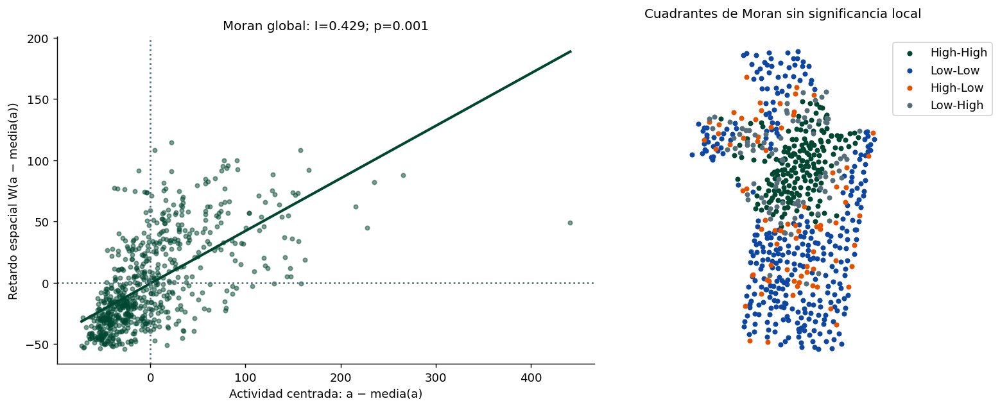

In [23]:
moran = report["spatial_autocorrelation"]
display(Markdown(f"**Resultado global.** I = {moran['i']:.6f}; "
                 f"pseudo-p = {moran['p_value']:.3f}, unilateral."))
display(result["moran_sensitivity"])
stations = result["stations"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.regplot(data=stations, x="moran_centered_activity", y="moran_spatial_lag",
            ci=None, ax=axes[0], color=GREEN, scatter_kws={"s": 12, "alpha": 0.5})
axes[0].axhline(0, color=GRAY, ls=":"); axes[0].axvline(0, color=GRAY, ls=":")
axes[0].set(xlabel="Actividad centrada: a − media(a)", ylabel="Retardo espacial W(a − media(a))",
            title=f"Moran global: I={moran['i']:.3f}; p={moran['p_value']:.3f}")
palette = {"High-High": GREEN, "Low-Low": BLUE, "High-Low": "#E65100", "Low-High": GRAY}
for label, color in palette.items():
    stations[stations.moran_quadrant.eq(label)].plot(
        ax=axes[1], color=color, markersize=12, label=label)
axes[1].set_title("Cuadrantes de Moran sin significancia local")
axes[1].set_axis_off(); axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout(); plt.show()

**Resultado.** El I de Moran global es **I = 0.429, p = 0.001** sobre las 677
estaciones: la autocorrelación espacial de la actividad es positiva y fuerte.
En 999 barajadas al azar, ninguna alcanzó el valor observado. Las estaciones
activas forman manchas geográficas, no una distribución espolvoreada.

El mapa clasifica cada estación según dos magnitudes: su propia actividad
centrada ($z_i$) y el promedio ponderado de sus 8 vecinas ($Wz_i$). El par
$(z_i, Wz_i)$ ubica a cada punto en un cuadrante:

- **High–High:** estación activa rodeada de vecinas activas.
- **Low–Low:** estación floja rodeada de flojas.
- **High–Low / Low–High:** valores atípicos respecto a su entorno.

**Por qué no es LISA.** El análisis LISA (*Local Indicators of Spatial
Association*) agrega, además de la clasificación, una **prueba de
significancia local por estación**: permutaciones condicionadas a cada punto
y corrección por comparaciones múltiples (677 pruebas simultáneas). Este
cuaderno realiza únicamente la clasificación por cuadrantes, sin ejecutar las
permutaciones locales. Por ello el mapa se titula *«Cuadrantes de Moran sin
significancia local»*: los puntos High–High describen un patrón, pero **no se
afirma que sean hotspots estadísticamente significativos**. Ambos conceptos
están relacionados —el Moran global refleja cuánto pesan HH y LL sobre HL y
LH— pero la etiqueta «LISA» queda reservada para cuando se demuestre
significancia local.

**Alcance:** el Moran describe la estructura de la red *existente*. Mide
autocorrelación de actividad entre estaciones instaladas; no demuestra por
sí solo concentración en toda la ciudad ni comportamiento en AGEBs sin
estaciones.

## 7. Actividad terciaria: proxy retrospectivo DENUE 2026

El directorio de 2026 no reconstruye el stock de establecimientos de 2025.
Excluir altas posteriores evita incorporar esas altas conocidas, pero no
recupera cierres ni cambios previos de ubicación, actividad o tamaño. La fecha
de alta en DENUE tampoco demuestra fecha de apertura. Las fechas desconocidas
se excluyen de esta cohorte y se contabilizan, sin imputar antigüedad.

Se incluyen explícitamente los sectores SCIAN 43, 46, 48, 49, 51–56, 61, 62,
71, 72, 81 y 93: comercio, transporte, servicios y gobierno. Se excluyen sectores
primarios, manufactura, construcción y electricidad. La medida sigue siendo
un proxy de personal ocupado registrado, no empleo formal observado ni empleo
residente de la AGEB.

Los estratos cerrados se convierten a sus puntos medios. Para «251 y más» no
existe punto medio identificable: 300 es únicamente el escenario de referencia,
contrastado con 251, 500 y 1,000. No se asignan tres personas a estratos desconocidos.
Un cero agregado significa ausencia de establecimientos elegibles y emparejados
en este directorio, no ausencia demostrada de empleos durante 2025.

In [24]:
display(pd.Series({k: v for k, v in report["denue_retrospective_proxy"].items()
                   if k != "open_band_sensitivity"}, name="value").to_frame())
display(pd.DataFrame({"included_scian_sector": CONFIG["tertiary_scian_sectors"]}))
display(result["employment_sensitivity"])

,value
snapshot_years,[2026]
input_establishments,462732
registration_after_2025,9627
registration_unknown,36
tertiary_with_known_registration_through_2025,419221
tertiary_unmatched_ageb,1357
tertiary_open_employment_band,1612
historical_2025_stock_reconstructed,False


,included_scian_sector
0,43
1,46
2,48
3,49
4,51
5,52
6,53
7,54
8,55
9,56


,open_band_assumption,pearson_log1p,spearman
0,251,0.284642,0.325456
1,300,0.285169,0.327655
2,500,0.285618,0.321590
3,1000,0.282892,0.307643


### 5.1. Mapa de actividad económica por AGEB (score DENUE)

Se construye un score heurístico de actividad económica por polígono a partir
del universo terciario elegible del DENUE —establecimientos con alta
registrada hasta 2025 y código SCIAN de sector terciario, sobre el snapshot
2026—. El score combina tres componentes, cada una transformada con `log1p`
(por las colas pesadas) y normalizada al rango [0, 1]:

- **Empleo proxy (50 %):** suma de puntos medios por estrato ocupacional,
  con el estrato abierto «251 y más» valorado en 300 empleados.
- **Establecimientos (30 %):** conteo de unidades terciarias elegibles.
- **Diversidad sectorial (20 %):** número de sectores SCIAN de dos dígitos
  distintos presentes.

El resultado se escala a [0, 100]. Es un índice *relativo* entre AGEBs de
este snapshot: un cero indica ausencia de establecimientos elegibles en el
corte, **no** cero empleos en 2025. El DENUE 2026 no reconstruye el stock
histórico; el score es un proxy retrospectivo comparable entre polígonos,
no una medición de actividad económica en pesos ni puestos reales.

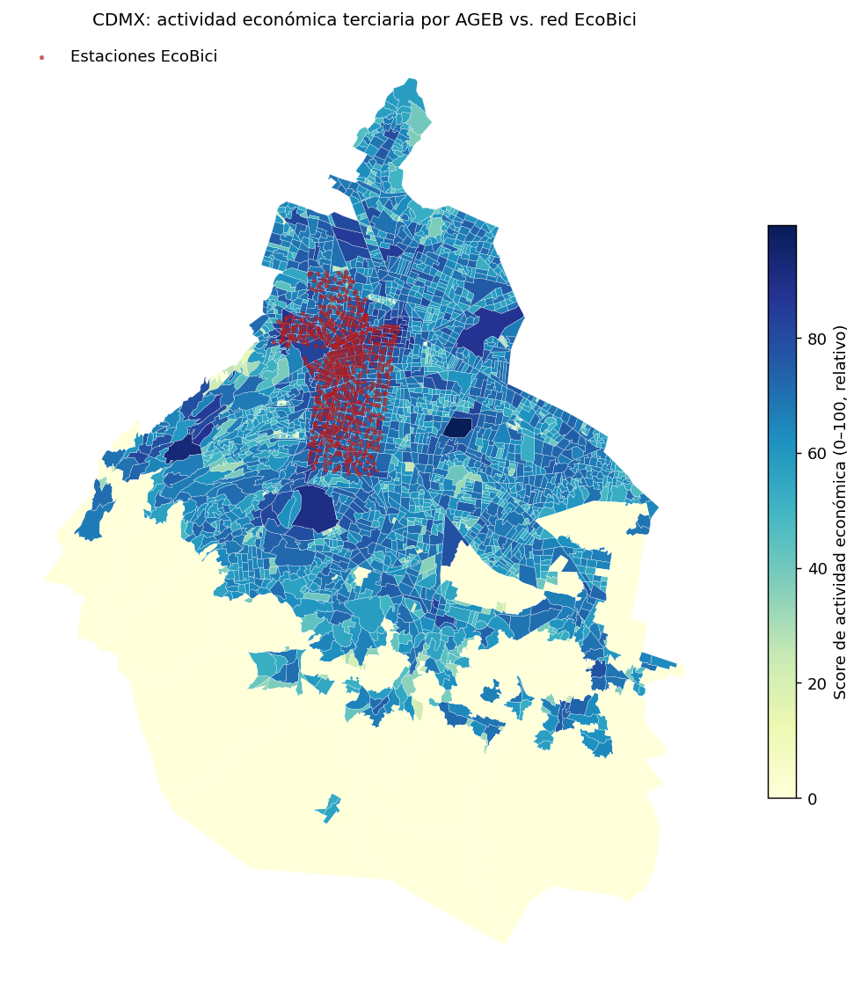

**Lectura.** El score oscila entre 0.0 y 99.6; mediana = 63.8. 40 AGEBs quedan en cero por ausencia de establecimientos elegibles en el snapshot. La sobreposición con la red permite ver si los polígonos de mayor actividad económica coinciden —o no— con la cobertura actual.

In [25]:
from V3.src.eda02_analysis import denue_proxy

# Universo terciario elegible (mismas reglas del EDA: SCIAN terciario + alta <= 2025)
denue = data["frames"]["denue"]
dates = denue.fecha_alta_parsed
eligible = denue.loc[
    dates.notna() & dates.dt.year.le(2025)
    & denue.codigo_act.astype("string").str[:2].isin(CONFIG["tertiary_scian_sectors"])
].copy()

# Diversidad sectorial: sectores SCIAN de 2 dígitos distintos por AGEB
eligible["sector"] = eligible.codigo_act.astype("string").str[:2]
diversity = (eligible.loc[eligible.cvegeo.isin(result["agebs"].cvegeo)]
             .groupby("cvegeo")["sector"].nunique()
             .rename("sectores_distintos"))

# Empleo proxy y conteo por AGEB (misma función auditada, banda abierta = 300)
denue_agg, _ = denue_proxy(denue, result["agebs"], 300)
score_df = (result["agebs"][["cvegeo", "geometry"]]
            .merge(denue_agg, on="cvegeo", validate="one_to_one")
            .merge(diversity, on="cvegeo", how="left", validate="one_to_one"))
score_df["sectores_distintos"] = score_df.sectores_distintos.fillna(0)

def _norm01(series):
    v = np.log1p(series.astype(float))
    span = v.max() - v.min()
    return (v - v.min()) / span if span > 0 else v * 0.0

score_df["score_economico"] = (100 * (
    0.50 * _norm01(score_df.empleo_terciario_proxy)
    + 0.30 * _norm01(score_df.establecimientos_terciarios)
    + 0.20 * _norm01(score_df.sectores_distintos)))

fig, ax = plt.subplots(figsize=(9, 9))
score_df.plot(column="score_economico", cmap="YlGnBu", legend=True, ax=ax,
              edgecolor="white", linewidth=0.15,
              legend_kwds={"label": "Score de actividad económica (0–100, relativo)",
                           "shrink": 0.6})
result["stations"].plot(ax=ax, color="#B71C1C", markersize=4, alpha=0.55,
                        label="Estaciones EcoBici")
ax.legend(loc="upper left", frameon=False)
ax.set_axis_off()
ax.set_title("CDMX: actividad económica terciaria por AGEB vs. red EcoBici")
plt.tight_layout(); plt.show()

display(Markdown(
    f"**Lectura.** El score oscila entre {score_df.score_economico.min():.1f} y "
    f"{score_df.score_economico.max():.1f}; mediana = {score_df.score_economico.median():.1f}. "
    f"{int((score_df.score_economico == 0).sum())} AGEBs quedan en cero por ausencia de "
    "establecimientos elegibles en el snapshot. La sobreposición con la red permite ver "
    "si los polígonos de mayor actividad económica coinciden —o no— con la cobertura actual."
))

## 8. Proximidad a paradas GTFS

La variable principal mide distancia euclidiana a cualquier parada aceptada
del feed. No se denomina «efecto Metro». Las referencias stop_times → trips →
routes permiten identificar agencias y tipos de ruta; el vínculo al calendario
muestra cobertura temporal declarada, no prueba histórica de posición o servicio.
La distancia principal mantiene todas las paradas para conservar su definición,
pero identifica paradas sin viajes aceptados y sin calendario vinculado a 2025.

Las rutas incluyen RTP y transporte concesionado, además de modos masivos.
La distribución empírica de agencias más cercanas permite comprobar qué mide
la variable. Las métricas específicas de Metro o por modo deberán construirse
con universos explícitos antes de utilizarlas como atributos de modelado.

,value
distance_universe,all accepted GTFS stops; not Metro-only or 202...
accepted_stops,11362
stops_linked_to_accepted_trips,10961
nearest_without_2025_calendar_link,21
calendar_link_is_not_proof_of_historical_stop_location,True


,nearest_to_ecobici
CC,344
RTP,118
MB,100
TROLE,57
METRO,26
unlinked_in_accepted_trips,21
MB|TROLE,10
CBB,1


,accepted_routes
3,282
1,13
6,3
0,1
2,1


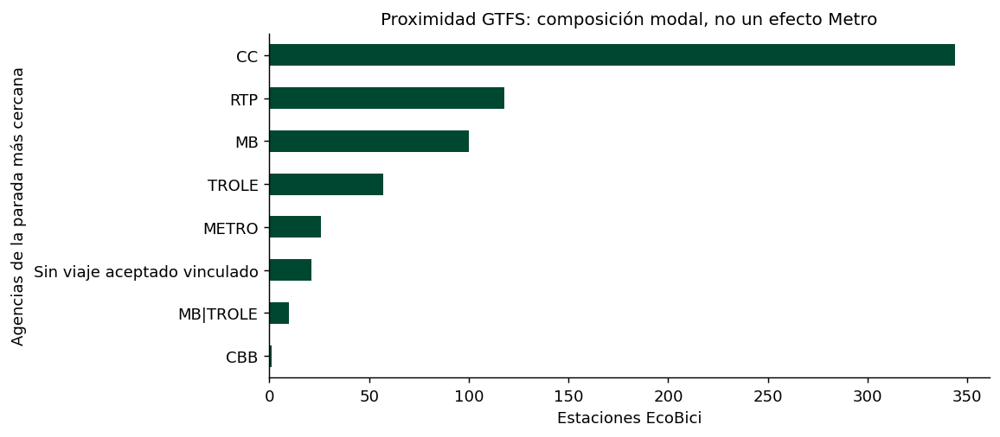

In [26]:
gtfs = report["gtfs_proximity"]
display(pd.Series({k: v for k, v in gtfs.items()
                   if k not in ("nearest_agency_counts", "route_type_counts")},
                  name="value").to_frame())
display(pd.Series(gtfs["nearest_agency_counts"], name="nearest_to_ecobici").to_frame())
display(pd.Series(gtfs["route_type_counts"], name="accepted_routes").to_frame())
counts = pd.Series(gtfs["nearest_agency_counts"]).rename(
    index={"unlinked_in_accepted_trips": "Sin viaje aceptado vinculado"}).sort_values()
counts.plot.barh(color=GREEN, figsize=(9, 4))
plt.xlabel("Estaciones EcoBici"); plt.ylabel("Agencias de la parada más cercana")
plt.title("Proximidad GTFS: composición modal, no un efecto Metro")
plt.tight_layout(); plt.show()

/var/folders/xy/k1hx31l15bq5npxk8h1gcpwc0000gn/T/ipykernel_42436/2575609831.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: LineString(zip(g.shape_pt_lon, g.shape_pt_lat))))


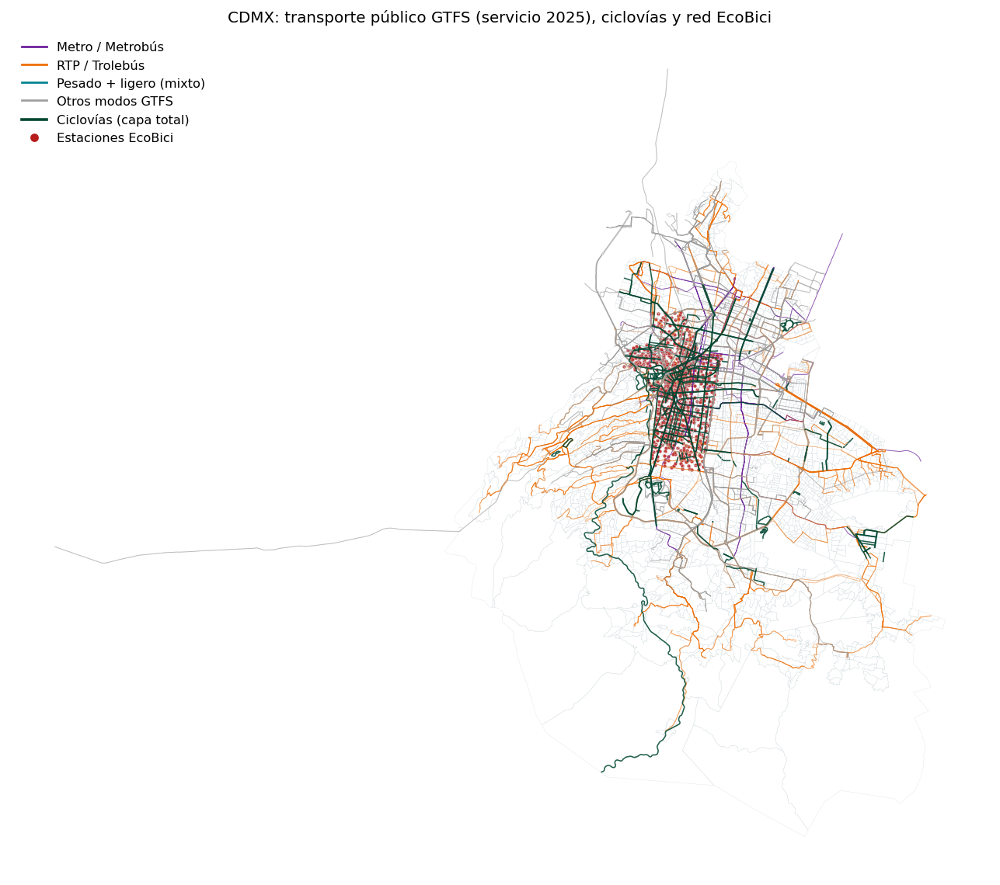

**Capas.** 674 trazados GTFS con calendario compatible con 2025 (de 674 shapes ligados a servicio), 651 tramos de ciclovía en la capa total y 677 estaciones. Los trazados GTFS provienen de shapes del feed —describen rutas planeadas, no trayectorias observadas— y la capa de ciclovías resume tipologías heterogéneas sin validar operatividad tramo a tramo.

In [28]:
from shapely.geometry import LineString
from matplotlib.lines import Line2D
import geopandas as gpd
from shapely.geometry import LineString
from matplotlib.lines import Line2D

proc = V3_DIR / "data/processed" / report["contract_id"]

# --- Ciclovías: capa 'Infraestructura ciclista total' ---
# (las capas 00-05 y 07 no son aditivas entre sí; la 06 es la total)
ciclo = gpd.read_parquet(proc / "ciclovias_capa_06.parquet")
if ciclo.crs is None:
    ciclo = ciclo.set_crs("EPSG:4326")
ciclo = ciclo.to_crs("EPSG:32614")

# --- GTFS: reconstruir líneas desde shapes y ligarlas a agencia ---
shapes = pd.read_parquet(proc / "gtfs_shapes.parquet",
    columns=["shape_id", "shape_pt_lat", "shape_pt_lon", "shape_pt_sequence"])
trips = pd.read_parquet(proc / "gtfs_trips.parquet",
                        columns=["trip_id", "route_id", "service_id", "shape_id"])
routes = pd.read_parquet(proc / "gtfs_routes.parquet",
                         columns=["route_id", "agency_id"])
calendar = pd.read_parquet(proc / "gtfs_calendar.parquet",
                           columns=["service_id", "has_2025_service"])

links = (trips[["shape_id", "route_id", "service_id"]]
         .dropna(subset=["shape_id"]).drop_duplicates()
         .merge(routes, on="route_id", validate="many_to_one")
         .merge(calendar, on="service_id", validate="many_to_one"))
links = links.loc[links.has_2025_service]

PESADO, LIGERO = {"METRO", "MB"}, {"RTP", "TROLE"}
def _grupo(agencies):
    a = set(agencies)
    if a & PESADO and a & LIGERO:
        return "Pesado + ligero (mixto)"
    if a & PESADO:
        return "Metro / Metrobús"
    if a & LIGERO:
        return "RTP / Trolebús"
    return "Otros modos GTFS"

shape_group = links.groupby("shape_id")["agency_id"].agg(_grupo).rename("grupo")
shapes = shapes.loc[shapes.shape_id.isin(shape_group.index)]
lines = (shapes.sort_values(["shape_id", "shape_pt_sequence"])
         .groupby("shape_id")
         .apply(lambda g: LineString(zip(g.shape_pt_lon, g.shape_pt_lat))))
gtfs_lines = gpd.GeoDataFrame(
    shape_group.reset_index(), geometry=lines.values,
    crs="EPSG:4326").to_crs("EPSG:32614")

# --- Mapa ---
fig, ax = plt.subplots(figsize=(10, 10))
result["agebs"].boundary.plot(ax=ax, color="#CFD8DC", linewidth=0.15)

colors = {"Metro / Metrobús": "#6A1B9A", "RTP / Trolebús": "#EF6C00",
          "Pesado + ligero (mixto)": "#00838F", "Otros modos GTFS": "#9E9E9E"}
for grupo, color in colors.items():
    subset = gtfs_lines.loc[gtfs_lines.grupo == grupo]
    if len(subset):
        subset.plot(ax=ax, color=color, linewidth=0.5, alpha=0.45)

ciclo.plot(ax=ax, color=GREEN, linewidth=0.9, alpha=0.85)
result["stations"].plot(ax=ax, color="#B71C1C", markersize=7, alpha=0.85,
                        edgecolor="white", linewidth=0.2)

handles = [Line2D([], [], color=c, lw=1.5, label=g) for g, c in colors.items()]
handles += [Line2D([], [], color=GREEN, lw=2, label="Ciclovías (capa total)"),
            Line2D([], [], marker="o", ls="", color="#B71C1C", ms=5,
                   label="Estaciones EcoBici")]
ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=9)
ax.set_axis_off()
ax.set_title("CDMX: transporte público GTFS (servicio 2025), ciclovías y red EcoBici")
plt.tight_layout(); plt.show()

display(Markdown(
    f"**Capas.** {len(gtfs_lines):,} trazados GTFS con calendario compatible con 2025 "
    f"(de {links.shape_id.nunique():,} shapes ligados a servicio), "
    f"{len(ciclo):,} tramos de ciclovía en la capa total y "
    f"{len(result['stations']):,} estaciones. "
    "Los trazados GTFS provienen de shapes del feed —describen rutas planeadas, "
    "no trayectorias observadas— y la capa de ciclovías resume tipologías "
    "heterogéneas sin validar operatividad tramo a tramo."
))

In [29]:
import folium
 
# Centro del mapa: promedio de las estaciones
center = [result["stations"].geometry.to_crs("EPSG:4326").y.mean(),
          result["stations"].geometry.to_crs("EPSG:4326").x.mean()]
m = folium.Map(location=center, zoom_start=12, tiles="cartodbpositron")
 
# --- Rutas GTFS por grupo modal (EPSG:4326 para folium) ---
colors_html = {"Metro / Metrobús": "#6A1B9A", "RTP / Trolebús": "#EF6C00",
               "Pesado + ligero (mixto)": "#00838F", "Otros modos GTFS": "#9E9E9E"}
gtfs_4326 = gtfs_lines.to_crs("EPSG:4326")
for grupo, color in colors_html.items():
    subset = gtfs_4326.loc[gtfs_4326.grupo == grupo]
    if subset.empty:
        continue
    layer = folium.FeatureGroup(name=f"GTFS: {grupo}")
    folium.GeoJson(
        subset[["geometry"]].__geo_interface__,
        style_function=lambda f, c=color: {"color": c, "weight": 1.5, "opacity": 0.5},
        smooth_factor=3.0,  # simplifica geometría para que el mapa no se vuelva pesado
    ).add_to(layer)
    layer.add_to(m)
 
# --- Ciclovías (capa total) ---
fg_ciclo = folium.FeatureGroup(name="Ciclovías (capa total)")
folium.GeoJson(
    ciclo.to_crs("EPSG:4326")[["geometry"]].__geo_interface__,
    style_function=lambda f: {"color": "#004731", "weight": 2.5, "opacity": 0.8},
    smooth_factor=3.0,
).add_to(fg_ciclo)
fg_ciclo.add_to(m)
 
# --- Estaciones EcoBici ---
fg_st = folium.FeatureGroup(name="Estaciones EcoBici")
for pt in result["stations"].geometry.to_crs("EPSG:4326"):
    folium.CircleMarker(
        location=[pt.y, pt.x], radius=3,
        color="#B71C1C", weight=1, fill=True, fill_color="#B71C1C",
        fill_opacity=0.85,
    ).add_to(fg_st)
fg_st.add_to(m)
 
# --- AGEBs como referencia tenue (opcional, se puede apagar) ---
fg_ageb = folium.FeatureGroup(name="Límites AGEB", show=False)
folium.GeoJson(
    result["agebs"].to_crs("EPSG:4326")[["geometry"]].__geo_interface__,
    style_function=lambda f: {"color": "#90A4AE", "weight": 0.4, "fill": False},
    smooth_factor=5.0,
).add_to(fg_ageb)
fg_ageb.add_to(m)
 
folium.LayerControl(collapsed=False).add_to(m)
m

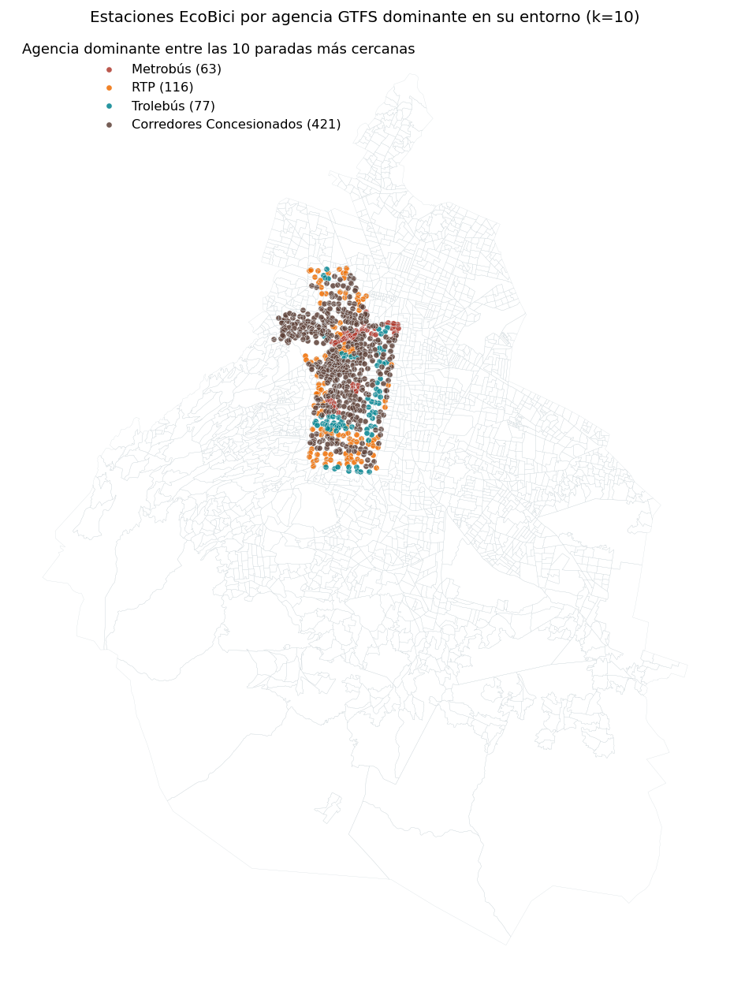

,estaciones
agencia_dominante,
Corredores Concesionados,421
RTP,116
Trolebús,77
Metrobús,63


**Regla.** Cada una de las 10 paradas GTFS más cercanas (distancia euclidiana, servicio compatible con 2025) vota por cada agencia que la sirve —una parada multimodal puede aportar a más de una agencia— y la estación adopta la agencia con más votos; los empates se resuelven alfabéticamente. La agencia dominante describe el *entorno* de la estación: no implica transferencia observada entre modos.

In [31]:
import geopandas as gpd
from scipy.spatial import cKDTree
from collections import Counter

proc = V3_DIR / "data/processed" / report["contract_id"]

# --- Parada -> conjunto de agencias que la sirven (servicio compatible con 2025) ---
stop_times = pd.read_parquet(proc / "gtfs_stop_times.parquet",
                             columns=["stop_id", "trip_id"])
trips_st = pd.read_parquet(proc / "gtfs_trips.parquet",
                           columns=["trip_id", "route_id", "service_id"])
routes_st = pd.read_parquet(proc / "gtfs_routes.parquet",
                            columns=["route_id", "agency_id"])
calendar_st = pd.read_parquet(proc / "gtfs_calendar.parquet",
                              columns=["service_id", "has_2025_service"])
links = (stop_times.merge(trips_st, on="trip_id", validate="many_to_one")
         .merge(routes_st, on="route_id", validate="many_to_one")
         .merge(calendar_st, on="service_id", validate="many_to_one"))
stop_agencies = (links.loc[links.has_2025_service]
                 .groupby("stop_id")["agency_id"].agg(lambda s: sorted(set(s))))

# --- Paradas con agencia conocida, en el CRS de las estaciones ---
stops = pd.read_parquet(proc / "gtfs_stops.parquet",
                        columns=["stop_id", "stop_lat", "stop_lon"])
stops = stops.loc[stops.stop_id.isin(stop_agencies.index)].copy()
stops_m = gpd.GeoDataFrame(
    stops, geometry=gpd.points_from_xy(stops.stop_lon, stops.stop_lat),
    crs="EPSG:4326").to_crs("EPSG:32614")

# --- 10 paradas más cercanas por estación; cada parada vota por sus agencias ---
tree = cKDTree(np.c_[stops_m.geometry.x, stops_m.geometry.y])
station_xy = np.c_[result["stations"].geometry.x, result["stations"].geometry.y]
_, idx = tree.query(station_xy, k=10)

votes = []
for row in idx:
    tally = Counter()
    for agency_set in stop_agencies.loc[stops_m.iloc[row].stop_id]:
        tally.update(agency_set)
    # ganador: más votos; empate se rompe por orden alfabético (determinista)
    winner = max(sorted(tally), key=lambda a: (tally[a], a))
    votes.append(winner)

stations_col = result["stations"].copy()
stations_col["agencia_dominante"] = votes

agency_names = {"CBB": "Cablebús", "CC": "Corredores Concesionados",
                "INTERURBANO": "Tren El Insurgente", "MB": "Metrobús",
                "METRO": "Metro", "PUMABUS": "Pumabús", "RTP": "RTP",
                "SUB": "Tren Suburbano", "TL": "Tren Ligero", "TROLE": "Trolebús"}
agency_colors = {"METRO": "#6A1B9A", "MB": "#B03A2E", "RTP": "#EF6C00",
                 "TROLE": "#00838F", "CC": "#5D4037", "CBB": "#AD1457",
                 "SUB": "#37474F", "INTERURBANO": "#455A64",
                 "TL": "#F9A825", "PUMABUS": "#1E88E5"}

# --- Mapa ---
fig, ax = plt.subplots(figsize=(10, 10))
result["agebs"].boundary.plot(ax=ax, color="#CFD8DC", linewidth=0.15)
for agency, color in agency_colors.items():
    subset = stations_col.loc[stations_col.agencia_dominante == agency]
    if len(subset):
        subset.plot(ax=ax, color=color, markersize=16, alpha=0.85,
                    edgecolor="white", linewidth=0.3,
                    label=f"{agency_names[agency]} ({len(subset)})")
ax.legend(loc="upper left", frameon=False, fontsize=9,
          title="Agencia dominante entre las 10 paradas más cercanas")
ax.set_axis_off()
ax.set_title("Estaciones EcoBici por agencia GTFS dominante en su entorno (k=10)")
plt.tight_layout(); plt.show()

display(stations_col.agencia_dominante.map(agency_names)
        .value_counts().rename("estaciones").to_frame())
display(Markdown(
    "**Regla.** Cada una de las 10 paradas GTFS más cercanas (distancia "
    "euclidiana, servicio compatible con 2025) vota por cada agencia que la "
    "sirve —una parada multimodal puede aportar a más de una agencia— y la "
    "estación adopta la agencia con más votos; los empates se resuelven "
    "alfabéticamente. La agencia dominante describe el *entorno* de la "
    "estación: no implica transferencia observada entre modos."
))

## 9. Asociaciones observadas: Pearson y Spearman

Pearson describe asociación lineal; Spearman describe asociación monotónica
entre rangos. Para Pearson del proxy de empleo se utiliza log1p; la transformación
no cambia sus rangos para Spearman. No se interpretan estas correlaciones como
elasticidades, efectos causales ni prueba de ausencia universal de relación.

Los p-valores bajo independencia se muestran únicamente como referencia.
Las estaciones comparten AGEB y tienen dependencia espacial. Los intervalos
exploratorios emplean 1,000 remuestreos de AGEBs con reemplazo, conservando juntas
sus estaciones. Este procedimiento no elimina dependencia entre AGEBs vecinas.
Se reportan muestra, transformación, número de AGEBs y ambas correlaciones,
sin escoger únicamente la medida más favorable a una narrativa.

,predictor,transform,n_stations,n_agebs,pearson_r,pearson_p_iid_reference,spearman_rho,spearman_p_iid_reference,pearson_ci_ageb_low,pearson_ci_ageb_high,spearman_ci_ageb_low,spearman_ci_ageb_high
0,densidad_pob_km2,identity,677,243,-0.137234,3.421695e-04,-0.062417,1.046674e-01,-0.248208,-0.013702,-0.185634,0.073870
1,dist_gtfs_m,identity,677,243,-0.247863,6.168549e-11,-0.241584,1.905416e-10,-0.306506,-0.182715,-0.317024,-0.159997
2,empleo_terciario_proxy,log1p,677,243,0.285169,3.915217e-14,0.327655,2.090026e-18,0.189709,0.380219,0.222220,0.430909


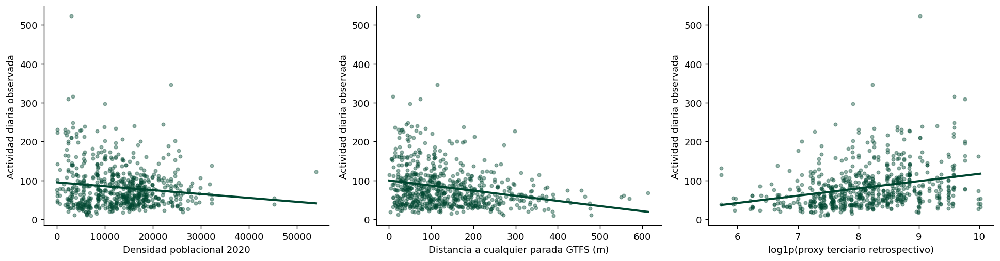

In [30]:
display(result["correlations"])
env = result["environment"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = [("densidad_pob_km2", "Densidad poblacional 2020"),
            ("dist_gtfs_m", "Distancia a cualquier parada GTFS (m)"),
            ("empleo_terciario_proxy", "log1p(proxy terciario retrospectivo)")]
for ax, (column, label) in zip(axes, features):
    x = env[column].astype(float)
    if column == "empleo_terciario_proxy":
        x = np.log1p(x)
    sns.regplot(x=x, y=env.viajes_diarios_prom.astype(float), ax=ax, ci=None,
                color=GREEN, scatter_kws={"s": 12, "alpha": 0.4})
    ax.set(xlabel=label, ylabel="Actividad diaria observada")
plt.tight_layout(); plt.show()

### 9.1. Segregación modal: Metro/Metrobús frente a RTP/Trolebús

Se construyen dist_transporte_pesado_m, exclusivamente con paradas asociadas
a agencias METRO y MB, y dist_transporte_ligero_m, con RTP y TROLE. Los nombres
«pesado» y «ligero» son agrupaciones operativas de este análisis, no una
clasificación técnica del peso vehicular. CC, Cablebús, tren suburbano y
otros modos no se incorporan a esos dos grupos.

Las paradas se identifican mediante stop_times, trips, routes y calendar
aceptados, restringidos a calendarios con cobertura declarada de 2025.
Esto no reconstruye su ubicación histórica ni garantiza servicio efectivo.
Una parada usada por ambas familias puede pertenecer a ambos conjuntos:
se documenta el solapamiento en lugar de asignar un modo arbitrario.

Se compara Spearman con actividad anual de las estaciones existentes.
Una mayor magnitud describe asociación monotónica, no «verdadero impacto»
causal en adopción individual. Persisten selección de ubicaciones, oferta,
centralidad urbana y dependencia espacial. Los intervalos bootstrap por
AGEB tienen las mismas limitaciones del apartado anterior.

,predictor,transform,n_stations,n_agebs,pearson_r,pearson_p_iid_reference,spearman_rho,spearman_p_iid_reference,pearson_ci_ageb_low,pearson_ci_ageb_high,spearman_ci_ageb_low,spearman_ci_ageb_high
0,dist_transporte_pesado_m,identity,677,243,-0.341753,5.552002e-20,-0.419343,3.265438e-30,-0.405326,-0.279914,-0.500184,-0.339036
1,dist_transporte_ligero_m,identity,677,243,-0.081809,3.331673e-02,-0.069403,7.113029e-02,-0.156676,-0.001608,-0.166580,0.026557


,eligible_stop_universe
dist_transporte_pesado_m,"{'agencies': ['METRO', 'MB'], 'eligible_stop_i..."
dist_transporte_ligero_m,"{'agencies': ['RTP', 'TROLE'], 'eligible_stop_..."


**Universos.** 26 identificadores de parada aparecen en ambos grupos. Las correlaciones originales con todas las paradas GTFS se conservan sin modificación.

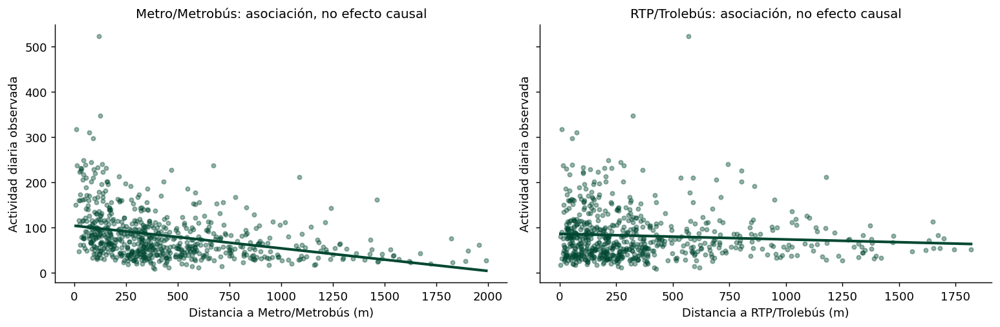

In [ ]:
modal_environment, modal_correlations, modal_info = modal_proximity(
    data["frames"], result["environment"])
result["modal_environment"] = modal_environment
result["modal_correlations"] = modal_correlations
report["modal_transport"] = modal_info
report["pending_validation"] = [
    "Monthly activity and Golden stability; station-level withdrawal/arrival imbalance"
    if item == "Monthly/hourly activity and Golden stability; withdrawals versus arrivals"
    else item for item in report["pending_validation"]
]
display(modal_correlations)
display(pd.Series(modal_info["groups"], name="eligible_stop_universe").to_frame())
display(Markdown(
    f"**Universos.** {modal_info['stop_ids_shared_between_groups']} identificadores "
    "de parada aparecen en ambos grupos. Las correlaciones originales con todas "
    "las paradas GTFS se conservan sin modificación."
))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
modal_labels = {"dist_transporte_pesado_m": "Metro/Metrobús",
                "dist_transporte_ligero_m": "RTP/Trolebús"}
for ax, (column, label) in zip(axes, modal_labels.items()):
    sns.regplot(data=modal_environment, x=column, y="viajes_diarios_prom",
                ax=ax, ci=None, color=GREEN, scatter_kws={"s": 12, "alpha": 0.4})
    ax.set(xlabel=f"Distancia a {label} (m)", ylabel="Actividad diaria observada",
           title=label + ": asociación, no efecto causal")
plt.tight_layout(); plt.show()

la actividad observada se asocia más con empleo y transporte cercano que con densidad residencial — lo que narra que EcoBici sirve flujos destino (trabajo/transporte), no solo origen (hogares). Pero son asociaciones entre estaciones existentes, no elasticidades ni efectos causales.

## 10. Golden Cluster y densidad de infraestructura

Las estaciones con actividad mayor o igual a P85 se asignan a sus AGEBs
anfitrionas únicas. Se publican ambos universos, sin suponer que 102 estaciones
representan 102 entornos independientes. La lista de AGEBs se deriva de las
llaves vigentes y no de un conteo histórico fijado manualmente.

La mediana de vecino cercano dentro del Golden Cluster describe **alta densidad
de infraestructura**. No demuestra canibalización: cercanía puede reflejar
complementariedad, capacidad o accesibilidad. El vecino Golden–Golden se busca
en un subconjunto distinto al vecino de toda la red, por lo que la comparación
no identifica un efecto de competencia.

No se deriva una separación óptima de 400 m. Cualquier restricción futura
requiere justificación de planificación y sensibilidad. Para el PCA debe
decidirse si cada AGEB pesa igual o si pesa según sus estaciones; son estimandos
distintos. En backtest el umbral y el perfil de referencia se estimarán solo
con la partición de entrenamiento cuando utilicen actividad observada.

,value
n_stations,102
n_unique_agebs,61
golden_neighbor_median_m,249.614528
network_neighbor_median_m,220.402917
cannibalization_identified,False
optimal_spacing_identified,False
ageb_pca_weighting,not decided by EDA; station and AGEB weighting...


,cvegeo,n_golden_stations,golden_mean_daily_activity
0,0901400010026,1,190.730137
1,0901400010223,1,136.346575
2,0901400010469,1,127.953425
3,0901400010717,1,160.708219
4,0901400010793,1,159.468493
...,...,...,...
56,0901600010660,1,239.867123
57,090160001068A,1,167.546575
58,0901600010779,1,228.336986
59,0901600010798,3,198.437443


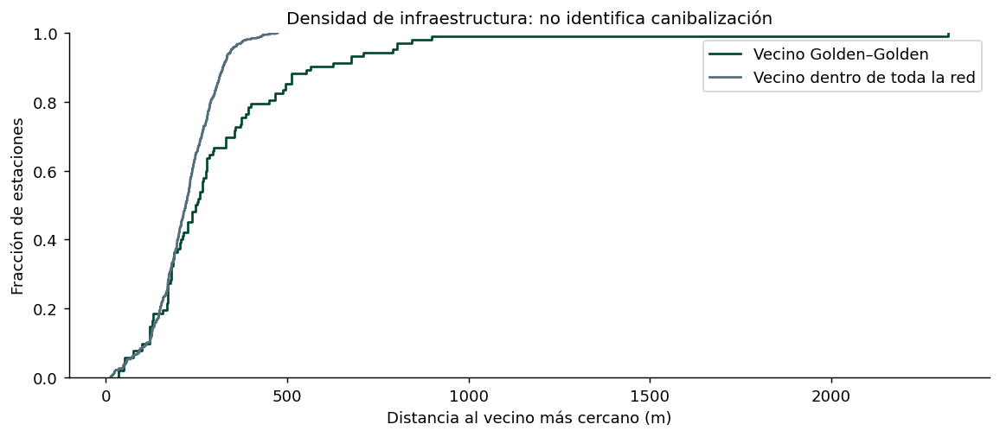

**Resultado.** 102 estaciones en 61 AGEBs únicas. Mediana Golden–Golden: 249.61 m; mediana de toda la red: 220.40 m.

In [ ]:
golden = report["golden_cluster"]
display(pd.Series({k: v for k, v in golden.items() if k != "ageb_ids"},
                  name="value").to_frame())
display(result["golden_agebs"][["cvegeo", "n_golden_stations",
                                "golden_mean_daily_activity"]])
fig, ax = plt.subplots(figsize=(9, 4))
sns.ecdfplot(result["golden_nn_m"], ax=ax, color=GREEN, label="Vecino Golden–Golden")
sns.ecdfplot(result["network_nn_m"], ax=ax, color=GRAY, label="Vecino dentro de toda la red")
ax.set(xlabel="Distancia al vecino más cercano (m)", ylabel="Fracción de estaciones",
       title="Densidad de infraestructura: no identifica canibalización")
ax.legend(); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Resultado.** {golden['n_stations']} estaciones en "
    f"{golden['n_unique_agebs']} AGEBs únicas. Mediana Golden–Golden: "
    f"{golden['golden_neighbor_median_m']:.2f} m; mediana de toda la red: "
    f"{golden['network_neighbor_median_m']:.2f} m."
))

**Nota metodológica: ¿qué es el Golden Cluster y por qué existe?**

El *Golden Cluster* es el subconjunto de estaciones que este proyecto adopta
como **referencia de éxito operativo**. Su definición es deliberadamente
simple y reproducible: todas las estaciones cuya actividad diaria observada
es mayor o igual al percentil 85 de la red.

- **Umbral:** P85 = 127.62 viajes diarios promedio.
- **Resultado:** 102 estaciones (el 15% superior de las 677).
- **Concentración:** esas 102 estaciones no viven en 102 entornos
  independientes — se agrupan en solo **61 AGEBs únicas**.

**¿Por qué P85 y no otro corte?** Es una decisión de diseño, no un valor
descubierto en los datos. Se busca una élite suficientemente pequeña para
describir un entorno característico, pero suficientemente grande para que
su perfil sea estable (con P95 quedarían ~34 estaciones; con P75 serían
~170 y el concepto de «élite» se diluiría). El cuaderno 03 documenta la
sensibilidad del centroide resultante a este umbral.

**¿Para qué sirve?** El Motor 1 (Expansión Estratégica) parte de la
hipótesis de que el *entorno* de las estaciones exitosas — densidad,
empleo, transporte cercano — puede caracterizarse y buscarse en AGEBs sin
cobertura. El Golden Cluster es el **conjunto de entrenamiento de ese
perfil**: sus 61 AGEBs anfitrionas definen el centroide en el espacio PCA
contra el que se mide la similitud de las candidatas. Sin este conjunto no
habría un «a qué parecerse» reproducible.

**Lectura correcta de sus distancias.** La mediana de separación entre
estaciones Golden es ~250 m. Esto describe **alta densidad de
infraestructura en la élite**, no «canibalización demostrada»: estaciones
cercanas pueden competir entre sí o complementarse (redundancia que
garantiza bicis y anclajes disponibles), y este análisis descriptivo no
distingue esos mecanismos. Tampoco se deriva de aquí una regla de
separación óptima — esa restricción pertenece al diseño del Motor 3.

**Límite explícito.** El Golden Cluster caracteriza *dónde funciona el
servicio hoy*. Una AGEB candidata puede ser ambientalmente idéntica a una
Golden y aun así no heredar su actividad si queda desconectada de la red:
el servicio requiere tomar una bici en una estación y devolverla en otra.
Por eso la similitud ambiental (Motor 1) se complementa con la
conectividad topológica (Motor 3), y por eso en el backtest el umbral P85
y el centroide se recalculan únicamente con la partición de entrenamiento.

## 11. Fuga de datos por construcción de variables




In [ ]:
display(pd.Series(report["leakage_audit"], name="value").to_frame())
display(Markdown(
    "**Resultado observado.** Spearman entre actividad y turnover_ratio: "
    f"{report['leakage_audit']['turnover_ratio_spearman']:.6f}. "
    "La identidad con el target impide utilizarlo como predictor de esa misma actividad."
))

,value
turnover_ratio_spearman,0.898384
n_valid_capacity,676
n_undefined_turnover,1
undefined_turnover_station_ids,[673]
undefined_turnover_reason,catalog capacity missing or nonpositive; stati...
turnover_ratio_definition,2 * daily_activity / catalog_capacity
turnover_ratio_predictor_eligible,False
pagerank_empirically_measured_here,False
same_period_od_centrality_predictor_eligible,False
models_trained,False


**Resultado observado.** Spearman entre actividad y turnover_ratio: 0.898384. La identidad con el target impide utilizarlo como predictor de esa misma actividad.

## 12. Alcance para atributos, validación y conectividad

Se conserva la información faltante y se compara su disponibilidad entre AGEBs
con y sin estación interna. El presente cuaderno no resuelve el MAUP ni produce
todavía una matriz PCA completa. Los atributos adicionales requieren contrato
de fuente, fecha, denominador, supresión y elegibilidad temporal.





In [ ]:
display(result["feature_coverage"])
display(pd.DataFrame({"pending_validation": report["pending_validation"]}))

,cohort,n_agebs,population_missing,density_missing,rural_missing_population,zero_matched_tertiary_establishments
0,with_internal_station,243,0,0,0,0
1,without_internal_station,2209,22,22,22,40


,pending_validation
0,Population-weighted and walking-network access...
1,Monthly activity and Golden stability; station...
2,"Spatial blocks/buffers, temporal eligibility a..."
3,Remove held-out observed flows before graph ba...
4,Physical connectivity and greedy baselines bef...


## 13. Publicación trazable de resultados

Los derivados EDA se publican fuera de la generación ETL inmutable, en una
carpeta identificada por el contrato y el hash de este análisis. Incluyen las
AGEBs Golden, entorno por estación, diagnóstico territorial, correlaciones y
sensibilidad, con linaje de contrato y versión analítica. La auditoría conserva
parámetros, versiones, hashes de insumos/código y verificaciones de salida.
Una ejecución fallida no reemplaza el cuaderno canónico; la auditoría activa se
actualiza después de guardar el cuaderno ejecutado. La versión previa queda archivada.

In [ ]:
report_path = stage_results(V3_DIR, data, result)
display(Markdown("**Cierre.** Diagnósticos calculados con observaciones verificadas. "
                 "Las limitaciones y requisitos pendientes permanecen explícitos."))
display(JSON({"eda_report_path": report_path.relative_to(V3_DIR).as_posix()}))

**Cierre.** Diagnósticos calculados con observaciones verificadas. Las limitaciones y requisitos pendientes permanecen explícitos.

<IPython.core.display.JSON object>